# 1 算子

一个复杂的机器学习模型（比如神经网络）可以看作一个复合函数，输入是数据特征，输出是标签的值或概率。简单起见，假设一个由$L$个函数复合的神经网络定义为：
$$
y=f_L(\cdots f_2(f_1(x))),
$$

其中$f_l(\cdot)$可以为带参数的函数，也可以为不带参数的函数，$x$为输入特征，$y$为某种损失。
我们将从$x$到$y$的计算看作一个前向计算过程。而神经网络的参数学习需要计算损失关于所有参数的偏导数（即梯度）。假设函数$f_l(\cdot)$包含参数$\theta_l$，根据链式法则，

$$
\begin{aligned}
\frac{\partial y}{\partial \theta_l} &= {\frac{\partial f_l}{\partial \theta_l}} \frac{\partial y}{\partial f_l} \\
&= \frac{\partial f_l}{\partial \theta_l} \frac{\partial f_{l+1}}{\partial f_l} \cdots \frac{\partial f_L}{\partial f_{L-1}} .
\end{aligned}
$$

在实践中，一种比较高效的计算$y$关于每个函数$f_l$的偏导数的方式是利用递归进行反向计算。令$\delta_l\triangleq \frac{\partial y}{\partial f_l}$，则有
$$
\delta_{l-1} = \frac{\partial f_l}{\partial f_{l-1}} \delta_{l}.
$$

如果将函数$f_l(\cdot)$称为前向函数，则$\delta_{l-1}$的计算称为函数$f(x)$的反向函数。

如果我们实现每个基础函数的前向函数和反向函数，就可以非常方便地通过这些基础函数组合出复杂函数，并通过链式法则反向计算复杂函数的偏导数。
在深度学习框架中，这些基本函数的实现称为算子(Operator，Op)。有了算子，就可以像搭积木一样构建复杂的模型。


# 2 算子定义
算子是构建复杂机器学习模型的基础组件，包含一个函数$f(x)$的前向函数和反向函数。为了可以更便捷地进行算子组合，本书中定义算子Op}的接口如下：

In [ ]:
class Op(object):
    def __init__(self):
        pass

    def __call__(self, inputs):
        return self.forward(inputs)

    # 前向函数
    # 输入：张量inputs
    # 输出：张量outputs
    def forward(self, inputs):
        # return outputs
        raise NotImplementedError

    # 反向函数
    # 输入：最终输出对outputs的梯度outputs_grads
    # 输出：最终输出对inputs的梯度inputs_grads
    def backward(self, outputs_grads):
        # return inputs_grads
        raise NotImplementedError

在上面的接口中，`forward`是自定义Op的前向函数，必须被子类重写，它的参数为输入对象，参数的类型和数量任意；`backward`是自定义Op的反向函数，必须被子类重写，它的参数为`forward`输出张量的梯度`outputs_grads`，它的输出为`forward`输入张量的梯度`inputs_grads`。

---
**笔记**  
在飞桨中，可以直接调用模型的`forward()`方法进行前向执行，也可以调用`__call__`，从而执行在`forward()`中定义的前向计算逻辑。

---

下面以$g = \exp(a \times b+c \times d)$为例，分别实现加法、乘法和指数运算三个算子，通过算子组合计算$y$值。

## 2.1 加法算子
图1展示了加法算子的前反向计算过程。</br>
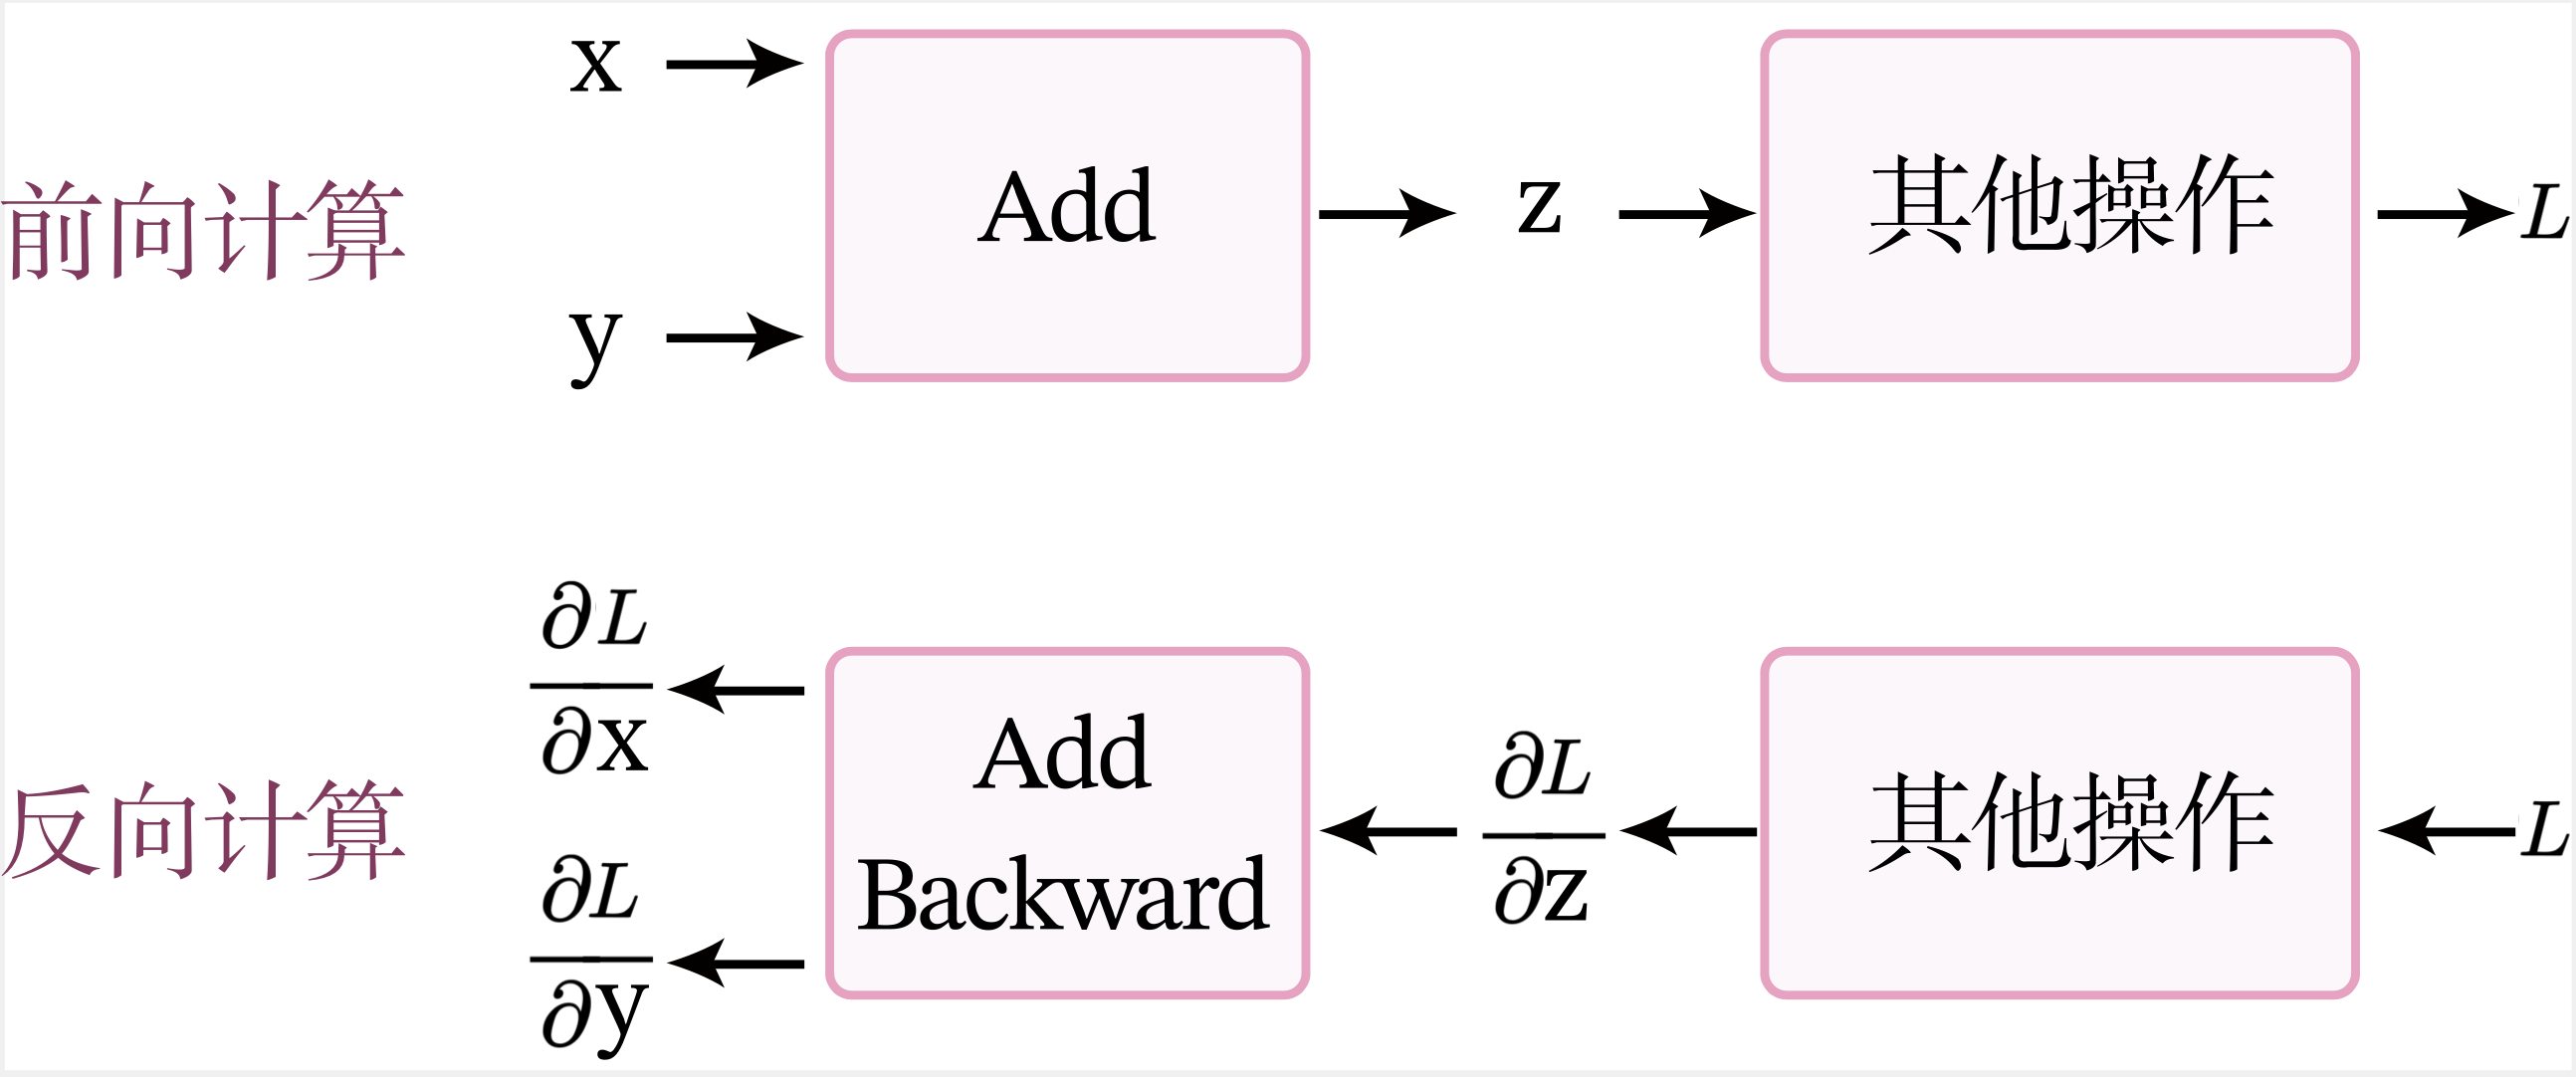
<center>图1 加法算子的前反向函数</center>
<br></br>

##### 前向计算  
当进行前向计算时，加法计算输出$z=x+y$。

##### 反向计算
假设经过一个其他操作后，最终输出为$L$，令$\delta_z=\frac{\partial L}{\partial z}$，$\delta_x=\frac{\partial L}{\partial x}$，$\delta_y=\frac{\partial L}{\partial y}$。
加法算子的反向计算的输入是梯度$\delta_z$，输出是梯度$\delta_x$和$\delta_y$。

根据链式法则，$\delta_x =  \delta_z \times 1$，$\delta_y =  \delta_z \times 1$。
加法算子的代码实现如下：

In [ ]:
class add(Op):
    def __init__(self):
        super(add, self).__init__()

    def __call__(self, x, y):
        return self.forward(x, y)

    def forward(self, x, y):
        self.x = x
        self.y = y
        outputs = x + y
        return outputs

    def backward(self, grads):
        grads_x = grads * 1
        grads_y = grads * 1
        return grads_x, grads_y

定义$x=1$、$y=4$，根据反向计算，得到$x$、$y$的梯度。

In [ ]:
x = 1
y = 4
add_op = add()
z = add_op(x, y)
grads_x, grads_y = add_op.backward(grads=1)
print("x's grad is: ", grads_x)
print("y's grad is: ", grads_y)

## 2.2 乘法算子
同理，乘法算子的代码实现如下：

In [ ]:
class multiply(Op):
    def __init__(self):
        super(multiply, self).__init__()

    def __call__(self, x, y):
        return self.forward(x, y)

    def forward(self, x, y):
        self.x = x
        self.y = y
        outputs = x * y
        return outputs

    def backward(self, grads):
        grads_x = grads * self.y
        grads_y = grads * self.x
        return grads_x, grads_y

## 2.3 指数算子
同理，指数算子的代码实现如下：

In [ ]:
import math

class exponential(Op):
    def __init__(self):
        super(exponential, self).__init__()

    def forward(self, x):
        self.x = x
        outputs = math.exp(x)
        return outputs

    def backward(self, grads):
        grads = grads * math.exp(self.x)
        return grads

__示例：__$y = \exp(a \times b+c \times d)$  
</br>分别指定$a、b、c、d$的值，通过实例化算子，调用加法、乘法和指数运算算子，计算得到$y$。

In [ ]:
a, b, c, d = 2, 3, 2, 2
# 实例化算子
multiply_op = multiply()
add_op = add()
exp_op = exponential()
f = exp_op(add_op(multiply_op(a, b), multiply_op(c, d)))
print('f: ', f)

---
**动手练习1** 

执行上述算子的反向过程，并验证梯度是否正确。

---



In [ ]:
'''*********************利用上述自定义算子，请在下面补充代码实现𝑦=exp(𝑎×𝑏+𝑐×𝑑)的反向梯度计算******************'''







"""*********************************************************************
   【注意】运行前，请把下面代码中的“张三”改为自己的，123456改为自己的。
   *********************************************************************"""
printLog('张三', 123456)

---
**动手练习2——用paddle自动微分实现** 

__注意：先学习参考后面的“3 自动微分机制”后再完成此部分__

---

In [ ]:
'''*********************利用paddle的自动微分，请在下面补充代码实现𝑦=exp(𝑎×𝑏+𝑐×𝑑)反向梯度计算******************'''






"""*********************************************************************
   【注意】运行前，请把下面代码中的“张三”改为自己的，123456改为自己的。
   *********************************************************************"""
printLog('张三', 123456)

# 3 自动微分机制
目前大部分深度学习平台都支持自动微分（Automatic Differentiation），即根据`forward()`函数来自动构建`backward()`函数。

---
**笔记**  

自动微分的原理是将所有的数值计算都分解为基本的原子操作，并构建\mykey{计算图}{Computational Graph}。计算图上每个节点都是一个原子操作，保留前向和反向的计算结果，很方便通过链式法则来计算梯度。自动微分的详细介绍可以参考《神经网络与深度学习》第4.5节。

---

飞桨的自动微分是通过`trace`的方式，记录各种算子和张量的前向计算，并自动创建相应的反向函数和反向变量，来实现反向梯度的计算。

---
**笔记**  

在飞桨中，可以通`过paddle.grad()`API或张量类成员函数x.grad来查看张量的梯度。

---
下面用一个比较简单的例子来了解整个过程。定义两个张量a和b，并用`stop_gradient`属性用来设置是否传递梯度。将a的`stop_gradient`属性设为False，会自动为a创建一个反向张量，将b的`stop_gradient`属性设为True，即不会为b创建反向张量。

In [ ]:
import paddle
# 定义张量a，stop_gradient=False代表进行梯度传导
a = paddle.to_tensor(2.0, stop_gradient=False)
# 定义张量b，stop_gradient=True代表不进行梯度传导
b = paddle.to_tensor(5.0, stop_gradient=True)
c = a * b
# 自动计算反向梯度
c.backward()
print("Tensor a's grad is: {}".format(a.grad))
print("Tensor b's grad is: {}".format(b.grad))
print("Tensor c's grad is: {}".format(c.grad))

下面我们解释下上面代码的执行逻辑。

## 3.1 前向执行
在上面代码中，第7行`c.backward()`被执行前，会为每个张量和算子创建相应的反向张量和反向函数。

当创建张量或执行算子的前向计算时，会自动创建反向张量或反向算子。这里以上面代码中乘法为例来进行说明。
1. 当创建张量a时，由于其属性`stop_gradient=False`，因此会自动为a创建一个反向张量，也就是图1.8中的a_grad。由于a不依赖其它张量或算子，a_grad的`grad_op`为None。
2. 当创建张量b时，由于其属性`stop_gradient=True`，因此不会为b创建一个反向张量。
3. 执行乘法$c=a\times b$ 时，$\times$是一个前向算子Mul，为其构建反向算子MulBackward。由于Mul的输入是a和b，输出是c，对应反向算子`MulBackward`的输入是张量c的反向张量`c_grad`，输出是a和b的反向张量。如果输入定义`stop_gradient=True`，反向张量即为None。在此例子中就是a_grad和None。
4. 反向算子MulBackward中的`grad_pending_ops`用于在自动构建反向网络时，明确该反向算子的下一个可执行的反向算子。可以理解为在反向计算中，该算子衔接的下一个反向算子。
5. 当c通过乘法算子Mul被创建后，c会创建一个反向张量c_grad，它的`grad_op`为该乘法算子的反向算子，即MulBackward。

由于此时还没有进行反向计算，因此这些反向张量和反向算子中的具体数值为空(data = None)。此时，上面代码对应的计算图状态如图2所示。</br>
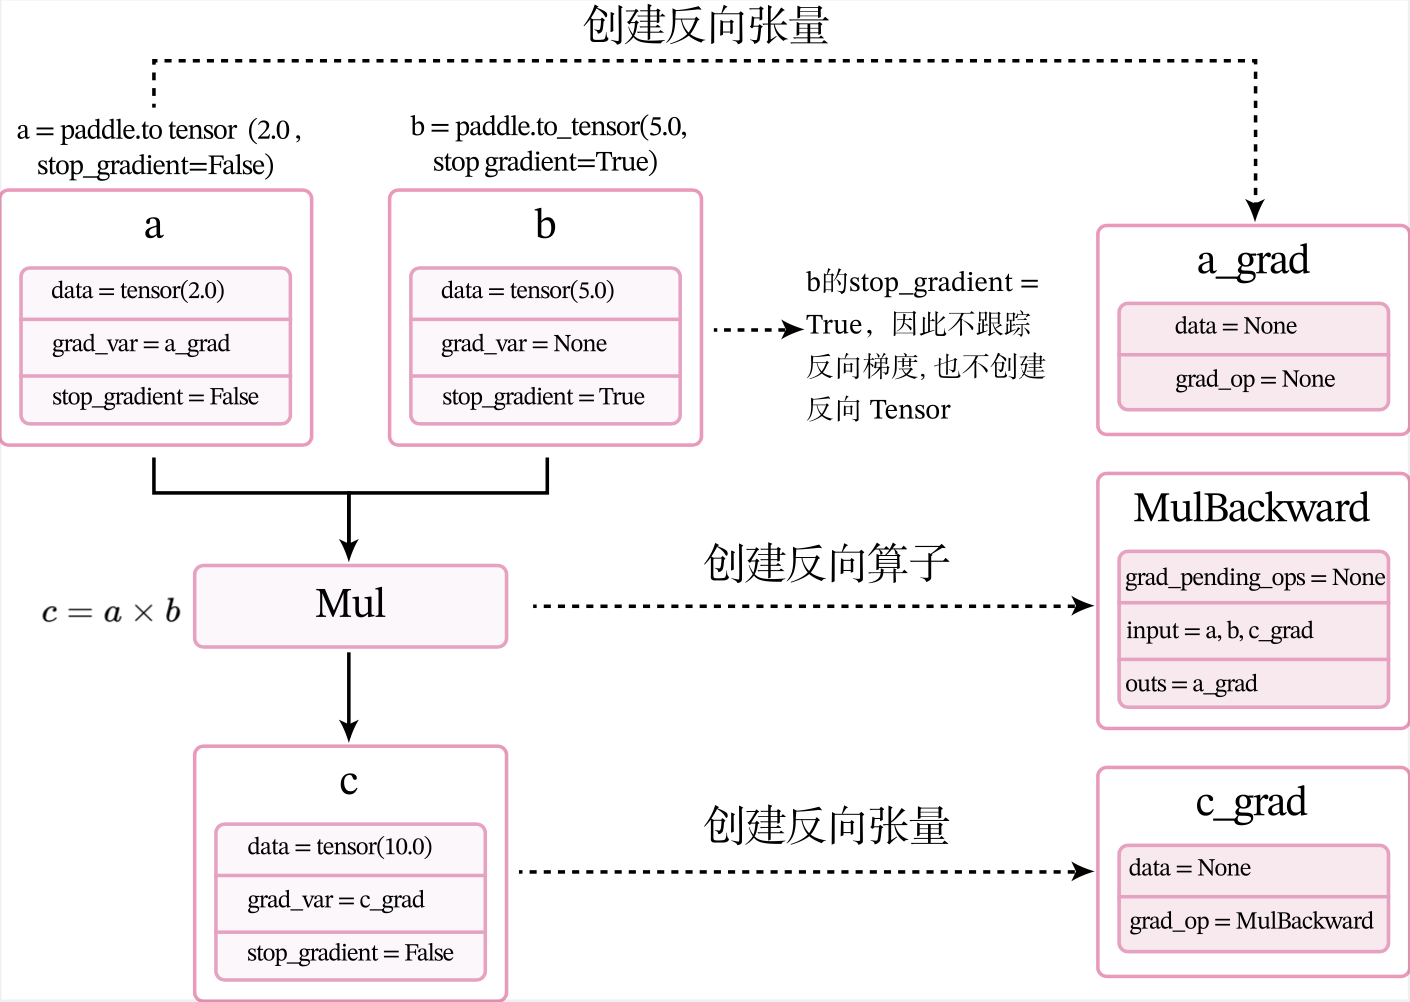
<center>图2 调用backward()前的计算图状态</center>
<br></br>

## 3.2 反向执行

调用`backward()`后，执行计算图上的反向过程，即通过链式法则自动计算每个张量或算子的微分，计算过程如图3所示。经过自动反向梯度计算，获得c_grad和a_grad的值。</br>
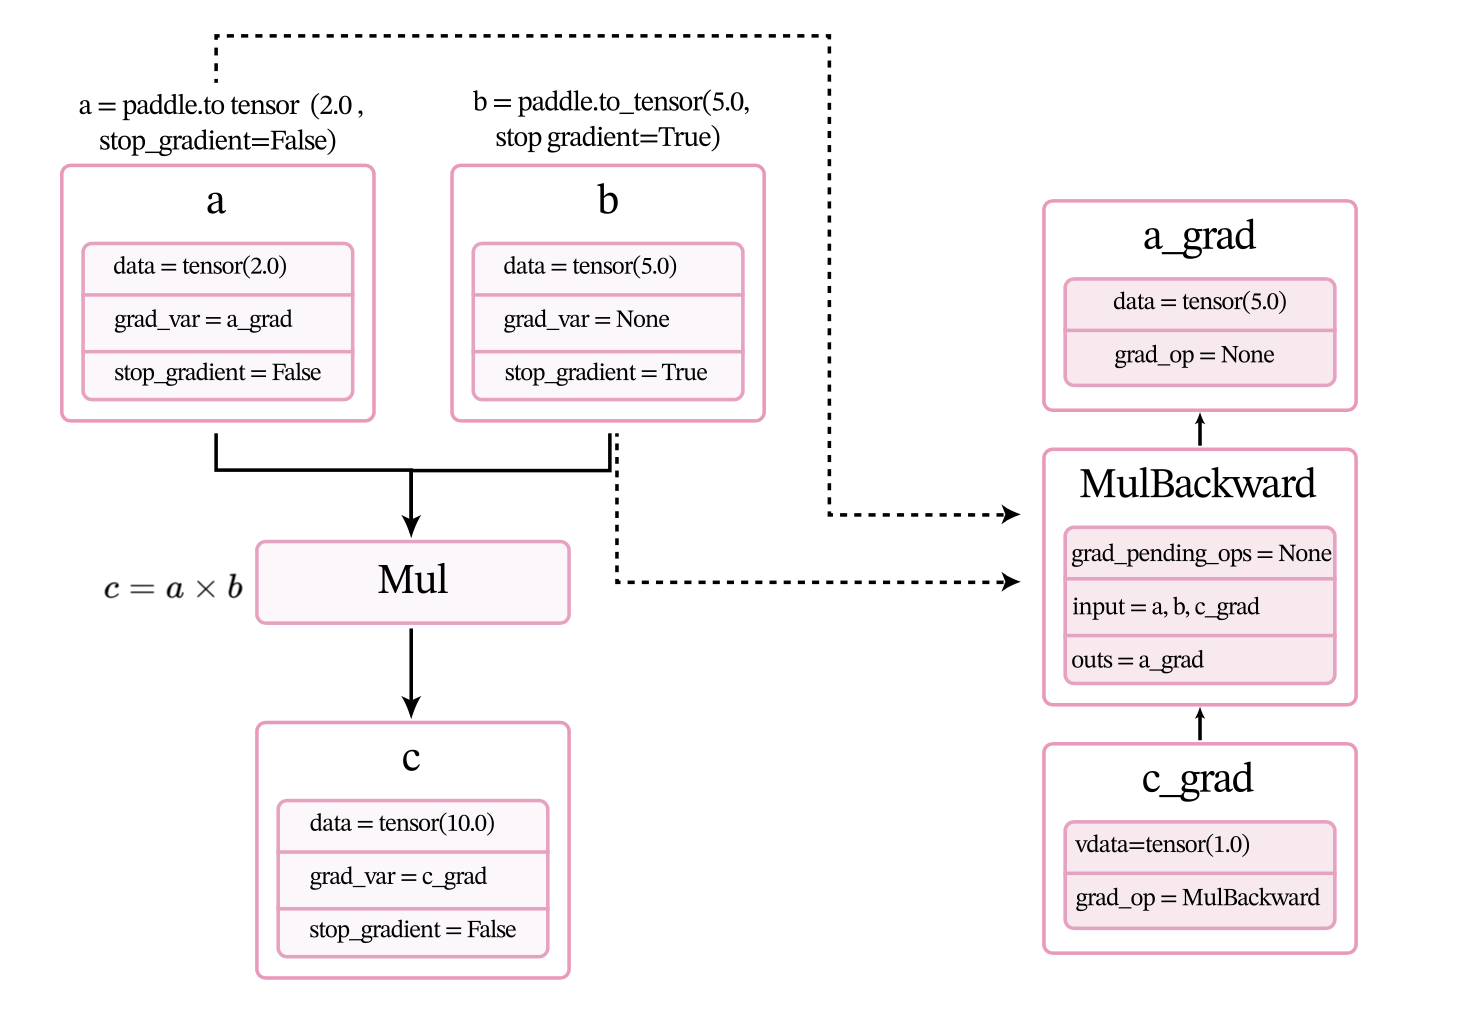
<br></br>
<center>图3 调用backward()后的计算图状态</center>
<br></br>

## 3.3 预定义的算子

从零开始构建各种复杂的算子和模型是一个很复杂的过程，在开发的过程中也难以避免地会出现很多冗余代码，因此飞桨提供了基础算子和中间算子，可以便捷地实现复杂模型。

在深度学习中，大多数模型都是以各种神经网络为主，由一系列层(Layer)组成，层是模型的基础逻辑执行单元。飞桨提供了`paddle.nn.Layer`类来方便快速地实现自己的层和模型。模型和层都可以基于`paddle.nn.Layer`扩充实现，模型只是一种特殊的层。

当我们实现的算子继承`paddle.nn.Layer`类时，就不用再定义`backward`函数。飞桨的自动微分机制可以自动完成反向传播过程，让我们只关注模型构建的前向过程，不必再进行烦琐的梯度求导。